# Small CNN
Small CNN trained on 128x128 aspect-ratio-preserving padded RGB inputs.
Loads the frozen split from `data/splits/patient_split.csv`

**Note:** `src/preprocessing.py` (Shashank's) is still a stub, so this notebook has a local, temporary
`load_and_pad` placeholder below. Once `src/preprocessing.py` is implemented, delete the placeholder
cell and switch the import back to `from src.preprocessing import load_and_pad`.

In [30]:
import sys
sys.path.append("..")

import kagglehub
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
torch.manual_seed(SEED)

# Prefer a GPU: CUDA on other platforms, MPS (Metal) on Apple Silicon, else fall back to CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", device)

Using device: mps


## Temporary local preprocessing (remove once `src/preprocessing.py` is implemented)

In [31]:
IMG_SIZE = 128

def load_and_pad(path: str, size: int = IMG_SIZE) -> np.ndarray:
    """TEMPORARY placeholder - mirrors what src/preprocessing.load_and_pad should do.
    Loads an RGB image, preserves aspect ratio, pads to a (size, size) square.
    """
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = size / max(w, h)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    img = img.resize((new_w, new_h), Image.BILINEAR)

    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    paste_x = (size - new_w) // 2
    paste_y = (size - new_h) // 2
    canvas.paste(img, (paste_x, paste_y))

    arr = np.asarray(canvas, dtype=np.float32) / 255.0  # scale to [0, 1]
    return arr

## Load the frozen split and build a Dataset/DataLoader
Images are loaded lazily per-batch.

In [32]:
manifest = pd.read_csv("../data/splits/patient_split.csv")
print(manifest["split"].value_counts())

# The manifest only stores filename + category, not an absolute path (those differ per machine).
# The path is rebuild the same way as 00_eda.ipynb (<kagglehub download root>/<category>/<filename>) 
download_path = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
data_dir = download_path / "cell_images"
if (data_dir / "cell_images").exists():
    data_dir = data_dir / "cell_images"

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}


class CellDataset(Dataset):
    def __init__(self, df: pd.DataFrame, data_dir: Path):
        self.df = df.reset_index(drop=True)
        self.data_dir = data_dir

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        path = self.data_dir / row["category"] / row["filename"]

        # Load the padded image as a (height, width, channels) array, then rearrange it to
        # (channels, height, width), since PyTorch's conv layers expect the channel dimension first.
        img = load_and_pad(str(path))
        img = torch.from_numpy(img).permute(2, 0, 1)

        label = CLASS_TO_IDX[row["category"]]
        return img, label


train_ds = CellDataset(manifest[manifest["split"] == "train"], data_dir)
val_ds = CellDataset(manifest[manifest["split"] == "val"], data_dir)
test_ds = CellDataset(manifest[manifest["split"] == "test"], data_dir)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

split
train    19124
val       4324
test      4110
Name: count, dtype: int64


## Small CNN

In [33]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes: int = 2):
        super().__init__()
        
        # Conv2d(in_channels, out_channels, kernel_size, padding): in_channels must match the
        # previous layer's out_channels (3 for the RGB input); padding=1 with a 3x3 kernel keeps
        # the spatial size unchanged, so only MaxPool2d(2) halves it (128 -> 64 -> 32 -> 16).
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 64 -> 32
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 32 -> 16
        )

        # Flatten turns the (64, 16, 16) feature map into one vector of 64*16*16 values, which
        # Linear(in_features, out_features) maps down to 128, then to num_classes.
        # Dropout(0.3) randomly zeroes 30% of activations during training to reduce overfitting.
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SmallCNN().to(device)
# Cross Entropy Loss = Binary Cross-Entropy as the classification is binary
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Training loop (validation only - freeze the protocol before touching test_loader)

In [34]:
from sklearn.metrics import (
    f1_score, roc_auc_score, roc_curve, confusion_matrix,
    precision_score, recall_score, precision_recall_curve,
)


def run_epoch(loader, train: bool):
    model.train(mode=train)
    total_loss, correct, n = 0.0, 0, 0
    all_labels, all_preds, all_probs = [], [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        n += images.size(0)

        # softmax turns the 2 raw logits (scores from model e.g. (1.2, -0.3)) into class 
        # probabilities that sum to 1; we keep index 1 (probability of "Parasitized") for 
        # ROC-AUC, which needs probabilities rather than hard 0/1 predictions.
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_labels.extend(labels.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_probs.extend(probs.detach().cpu().tolist())

    # Every metric below is computed once over the whole epoch's predictions, not averaged
    # per batch - a single batch's TP/FP/FN counts are too small and skewed on their own.
    # precision/recall/f1 here are measured at the default 0.5 decision threshold (argmax).
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)
    # fpr/tpr and pr_precision/pr_recall sweep every possible threshold, for the ROC and
    # precision-recall curves below - distinct from the single-threshold scores above.
    fpr, tpr, _ = roc_curve(all_labels, all_probs)
    pr_precision, pr_recall, _ = precision_recall_curve(all_labels, all_probs)

    return {
        "loss": total_loss / n,
        "acc": correct / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "cm": cm,
        "fpr": fpr,
        "tpr": tpr,
        "pr_precision": pr_precision,
        "pr_recall": pr_recall,
    }


NUM_EPOCHS = 5
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_precision": [], "val_precision": [],
    "train_recall": [], "val_recall": [],
    "train_f1": [], "val_f1": [],
    "train_auc": [], "val_auc": [],
}

for epoch in range(1, NUM_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)

    for key in ("loss", "acc", "precision", "recall", "f1"):
        history[f"train_{key}"].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])
    history["train_auc"].append(train_metrics["roc_auc"])
    history["val_auc"].append(val_metrics["roc_auc"])

    print(f"Epoch {epoch}: "
          f"train_loss={train_metrics['loss']:.4f} train_acc={train_metrics['acc']:.4f} "
          f"train_precision={train_metrics['precision']:.4f} train_recall={train_metrics['recall']:.4f} "
          f"train_f1={train_metrics['f1']:.4f} train_auc={train_metrics['roc_auc']:.4f} | "
          f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['acc']:.4f} "
          f"val_precision={val_metrics['precision']:.4f} val_recall={val_metrics['recall']:.4f} "
          f"val_f1={val_metrics['f1']:.4f} val_auc={val_metrics['roc_auc']:.4f}")
    print("val confusion matrix:\n", val_metrics["cm"])

# Keep the final epoch's val metrics around for the ROC/PR curve plots below.
final_val_metrics = val_metrics

Epoch 1: train_loss=0.4095 train_acc=0.8106 train_precision=0.8167 train_recall=0.8002 train_f1=0.8083 train_auc=0.8986 | val_loss=0.2584 val_acc=0.8883 val_precision=0.8642 val_recall=0.9333 val_f1=0.8974 val_auc=0.9669
val confusion matrix:
 [[1728  332]
 [ 151 2113]]
Epoch 2: train_loss=0.1805 train_acc=0.9400 train_precision=0.9403 train_recall=0.9394 train_f1=0.9399 train_auc=0.9754 | val_loss=0.1788 val_acc=0.9477 val_precision=0.9603 val_recall=0.9390 val_f1=0.9495 val_auc=0.9802
val confusion matrix:
 [[1972   88]
 [ 138 2126]]
Epoch 3: train_loss=0.1449 train_acc=0.9531 train_precision=0.9595 train_recall=0.9461 train_f1=0.9527 train_auc=0.9838 | val_loss=0.1680 val_acc=0.9487 val_precision=0.9566 val_recall=0.9448 val_f1=0.9507 val_auc=0.9815
val confusion matrix:
 [[1963   97]
 [ 125 2139]]
Epoch 4: train_loss=0.1291 train_acc=0.9571 train_precision=0.9676 train_recall=0.9456 train_f1=0.9565 train_auc=0.9876 | val_loss=0.1539 val_acc=0.9517 val_precision=0.9553 val_recall=0.

## Learning curves
Train vs. validation loss and accuracy across epochs - the proposal's "record learning curves" check.
A widening gap (train still improving, val flat/worsening) signals overfitting.

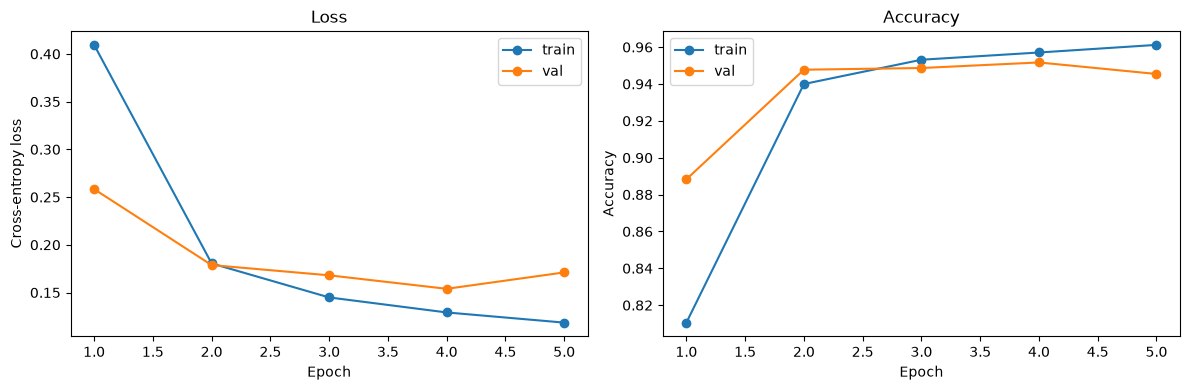

In [35]:
import matplotlib.pyplot as plt

epochs_range = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="train")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## ROC curve (final epoch, validation set)
The dashed diagonal is the random-guess baseline (AUC = 0.5): a model with no real discriminative
power would produce a ROC curve that tracks this line on average. The further the actual curve
bows toward the top-left corner (high true-positive rate at a low false-positive rate), the better
the model is than chance.

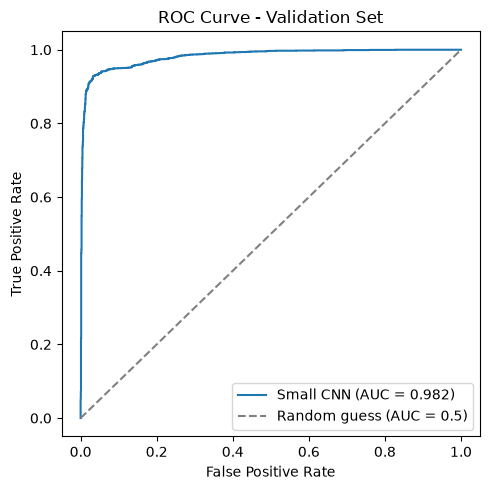

In [36]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_metrics["fpr"], final_val_metrics["tpr"],
         label=f"Small CNN (AUC = {final_val_metrics['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend()
plt.tight_layout()
plt.show()

## Precision-Recall curve (final epoch, validation set)
The dashed horizontal line is the random-guess baseline: a classifier with no real
discriminative power would have precision roughly equal to the positive class's share of
the validation set, regardless of recall. A curve staying above that line, especially as
recall approaches 1, means the model ranks true positives ahead of negatives better than chance.

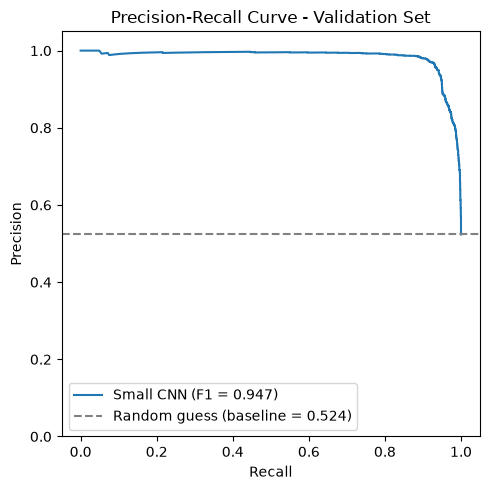

In [37]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_metrics["pr_recall"], final_val_metrics["pr_precision"],
         label=f"Small CNN (F1 = {final_val_metrics['f1']:.3f})")

# Baseline: the positive class's prevalence in the validation set (what a random classifier's
# precision would hover around, regardless of threshold/recall).
baseline = (val_ds.df["category"] == "Parasitized").mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Random guess (baseline = {baseline:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Validation Set")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

## Save the trained model
Writes the trained weights (plus the bits needed to use them later: image size, class index
mapping) to `models/cnn.pt`, so Shania can load this model for Grad-CAM without retraining it.

In [38]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "cnn.pt"

# Load with: checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
#            model = SmallCNN(); model.load_state_dict(checkpoint["model_state_dict"])
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": CLASS_TO_IDX,
    "img_size": IMG_SIZE,
    "val_metrics": {k: v for k, v in final_val_metrics.items() if k not in ("fpr", "tpr", "pr_precision", "pr_recall")},
}, MODEL_PATH)

print(f"Saved trained Small CNN to {MODEL_PATH}")

Saved trained Small CNN to ../models/cnn.pt
